My personal goal for this project is to hopefully improve my poor-ish python skills, as well as start to dip my toes into the field of digital archaeology. On an assignment level, I hope to be able to find the word relative word usage differences between the 2 different authors, as it could be interesting be able to identify two different writing styles between the authors.

The best way to achieve this goal would be to strategically use the template provided, as well as external research into python related issues to complete the provided code. Doing this will help achieve both goals.

**Didn't end up using** - (As for my idea, I want to compare two different books from different age ranges. For example, I would like to compare a book meant for adults and a book meant for young adults. These books would need to be similar genres, with similar topics.)

I decided that I would like to compare the works of two different authors that attempt to use the same dialect. An exmaple of this is two stories that are both set in Brooklyn, New York. The example I went with instead, however, is a comparison between two authors both writing character heavily using an 1800's southern dialect.

I would also like to potentially compare stories from two different perspectives ie first person and third person.

# Assignment 1

1. Compare word frequencies between two works of a single author.
1. Compare word frequencies between works of two authors.
1. Are there some words preferred by one author but used less frequently by another author?

Extra credit

1. The frequency of a specific word, e.g., "would" should follow a binomial distribution (each regular word in a document is a trial and with probability p that word is "would". The estimate for p is N("would")/N(regular word)). Do these binomial distributions for your chosen word differ significantly between books of the same author or between authors?

Project Gutenberg is a good source of for fiction and non-fiction.

E.g below are two most popular books from Project Gutenberg:
- Pride and Prejudice at http://www.gutenberg.org/ebooks/1342.txt.utf-8
- Adventures of Huckleberry Finn at http://www.gutenberg.org/ebooks/76.txt.utf-8

#Comparing Two Texts From the Same Author

---


###*Adventures of Huckleberry Finn* and *The Adventures of Tom Sawyer* by Mark Twain

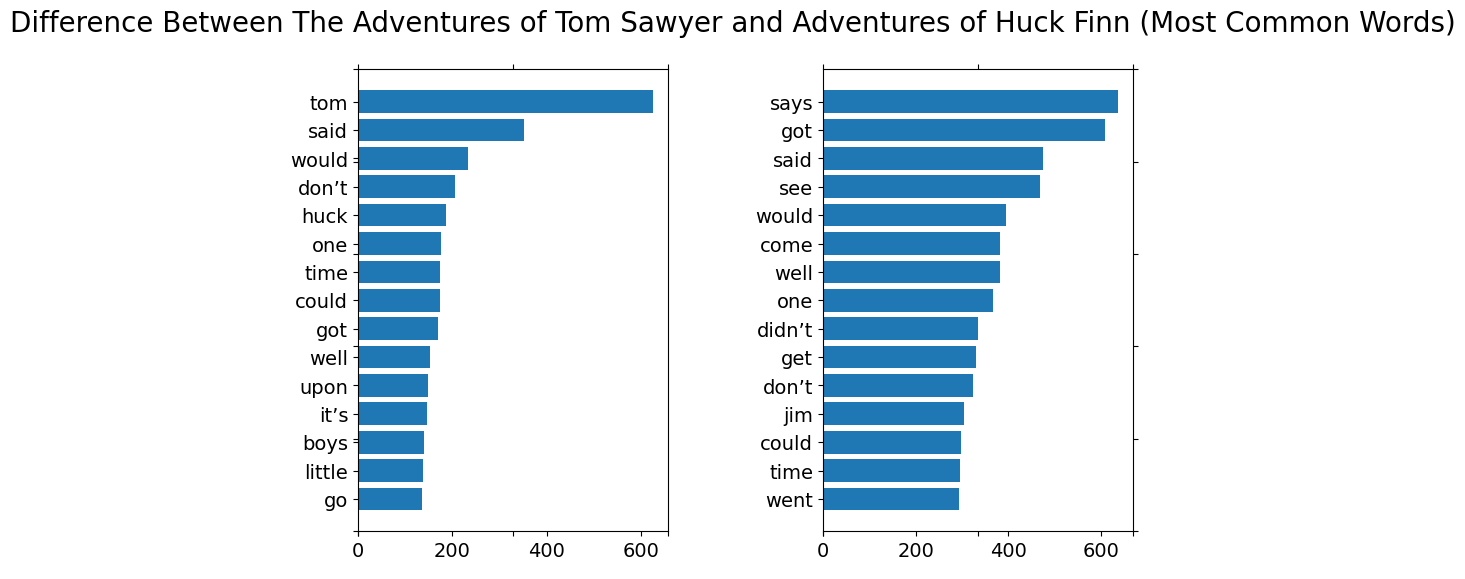

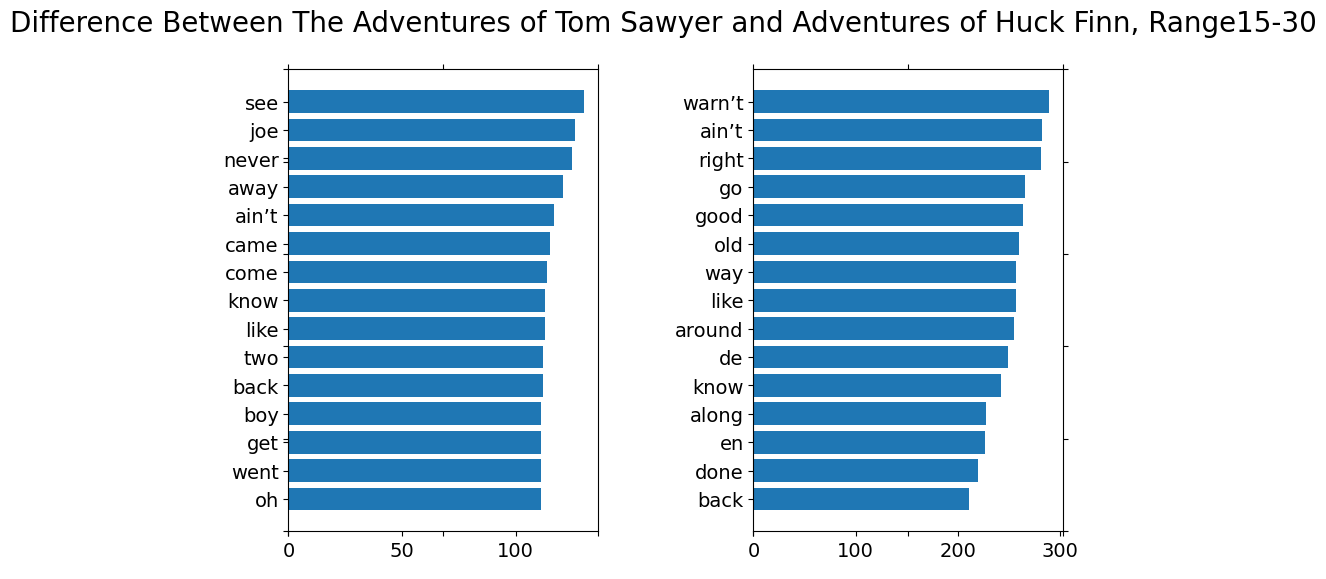

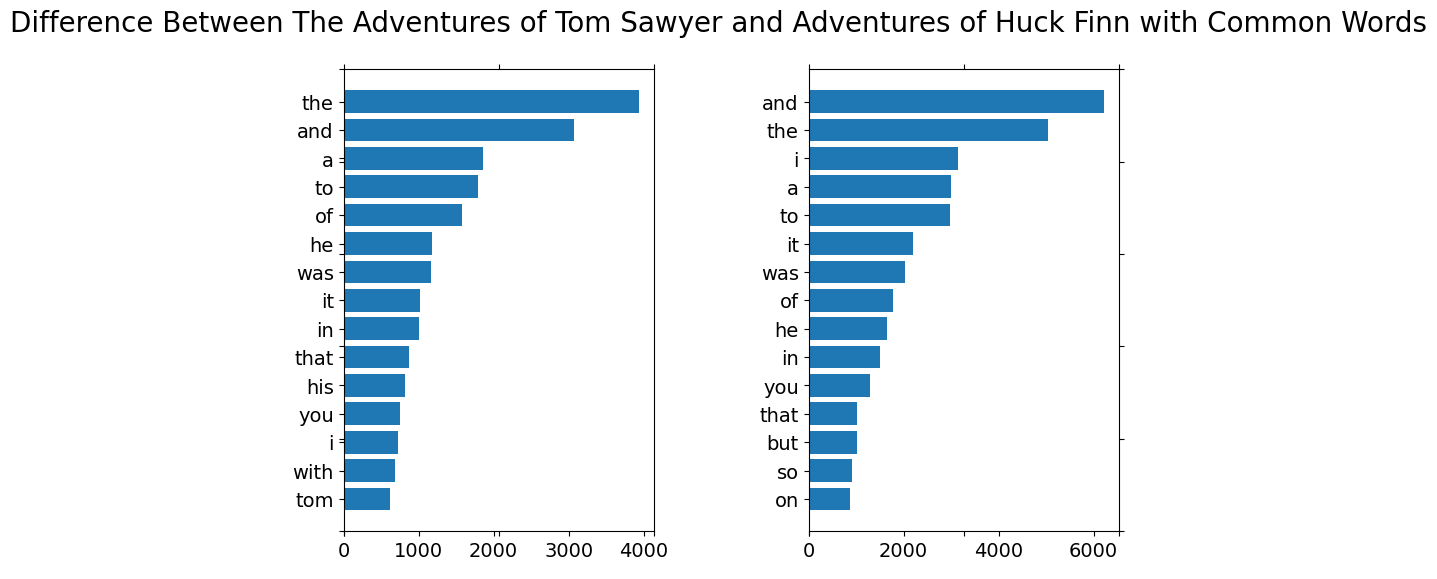

In [24]:
import requests, re, nltk
from bs4 import BeautifulSoup
from nltk import clean_html
from collections import Counter
import operator
import numpy as np
import pylab
import matplotlib.pyplot as plt

nltk.download('stopwords', quiet=True)
# we may not care about the usage of stop words
stop_words = nltk.corpus.stopwords.words('english') + [
 'ut', '\'re','.', ',', '--', '\'s', '?', ')', '(', ':', '\'',
 '"', '-', '}', '{', '&', '|', u'\u2014' ]

# We most likely would like to remove html markup
def cleanHtml (html):
    soup = BeautifulSoup(html, 'html.parser')
    return soup .get_text()

# We also want to remove special characters, quotes, etc. from each word
def cleanWord (w):
    wn = re.sub(r'[,"“.\'&|:@>*;/=]', "", w)
    return re.sub(r'^[0-9\.]*$', "", wn)

# Tom Sawyer Text
tSawyer = cleanHtml(requests.get('http://www.gutenberg.org/ebooks/74.txt.utf-8').text).lower()
# Huckleberry Finn text
tHuck = cleanHtml(requests .get('http://www.gutenberg.org/ebooks/76.txt.utf-8').text).lower()

# Split texts into wds and clean each word, filtering out empty strings
wdsSawyer = [cleanWord(w) for w in re.split(r'\s+',tSawyer) if cleanWord(w)]
wdsHuck = [cleanWord(w) for w in re.split(r'\s+',tHuck) if cleanWord(w)]

# Create dictionaries for each text
dSawyer = {}
for w in wdsSawyer:
    if w in dSawyer: dSawyer [w] = dSawyer [w] + 1
    else:  dSawyer [w] = 1

# Create dictionaries for each text
dHuck = {}
for w in wdsHuck:
    if w in dHuck: dHuck [w] = dHuck [w] + 1
    else:  dHuck [w] = 1

dSawyerCommon = dSawyer.copy()
dHuckCommon = dHuck.copy()

for k in stop_words:
    dSawyer.pop(k, None)
    dHuck.pop(k, None)

# Sort dictionaries
dsSawyer = sorted (dSawyer .items(), key = operator .itemgetter (1), reverse=True)
dsHuck = sorted (dHuck .items(), key = operator .itemgetter (1), reverse=True)
dsSawyerCommon = sorted (dSawyerCommon .items(), key = operator .itemgetter (1), reverse=True)
dsHuckCommon = sorted (dHuckCommon .items(), key = operator .itemgetter (1), reverse=True)

# Limit to top 15 for printing
mlSawyer = min(len(dsSawyer),15)
## Limit to top 15 for printing
#for i in range(1,mlSawyer,1):
#    print (dsSawyer[i][0]+"\t"+str(dsSawyer[i][1]))
#print("\n")
mlHuck = min(len(dsHuck),15)
## Limit to top 15 for printing
#for i in range(1,mlHuck,1):
#    print (dsHuck[i][0]+"\t"+str(dsHuck[i][1]))

%matplotlib inline
def plotTwoLists (wf_ee, wf_bu, title):
    f = plt.figure (figsize=(10, 6))
    # this is painfully tedious....
    f .suptitle (title, fontsize=20)
    ax = f.add_subplot(111)
    ax .spines ['top'] .set_color ('none')
    ax .spines ['bottom'] .set_color ('none')
    ax .spines ['left'] .set_color ('none')
    ax .spines ['right'] .set_color ('none')
    ax .tick_params (labelcolor='w', top='off', bottom='off', left='off', right='off', labelsize=20)

    # Create two subplots, this is the first one
    ax1 = f .add_subplot (121)
    plt .subplots_adjust (wspace=.5)

    pos = np .arange (len(wf_ee))
    ax1 .tick_params (axis='both', which='major', labelsize=14)
    pylab .yticks (pos, [ x [0] for x in wf_ee ])
    ax1 .barh (range(len(wf_ee)), [ x [1] for x in wf_ee ], align='center')

    ax2 = f .add_subplot (122)
    ax2 .tick_params (axis='both', which='major', labelsize=14)
    pos = np .arange (len(wf_bu))
    pylab .yticks (pos, [ x [0] for x in wf_bu ])
    ax2 .barh (range (len(wf_bu)), [ x [1] for x in wf_bu ], align='center')
    plt.show()


# Top 15 words for each story
dsSawyerTop = dsSawyer[0:mlSawyer][::-1]
dsHuckTop = dsHuck[0:mlHuck][::-1]
dsSawyerCommon = dsSawyerCommon[0:mlSawyer][::-1]
dsHuckCommon = dsHuckCommon[0:mlHuck][::-1]

# Less common words
skip_top = 15
take_next = 15

dsSawyerSlice = dsSawyer[skip_top : skip_top + take_next][::-1]
dsHuckSlice = dsHuck[skip_top : skip_top + take_next][::-1]

# Plot both versions
plotTwoLists(dsSawyerTop, dsHuckTop, 'Difference Between The Adventures of Tom Sawyer and Adventures of Huck Finn (Most Common Non-Common Words)')
print("\n")
plotTwoLists(dsSawyerSlice, dsHuckSlice, 'Difference Between The Adventures of Tom Sawyer and Adventures of Huck Finn, Range ' + str(skip_top) + ' - ' + str(skip_top + take_next))
print("\n")
plotTwoLists(dsSawyerCommon, dsHuckCommon, 'Difference Between The Adventures of Tom Sawyer and Adventures of Huck Finn with Common Words')



#1. Comparing word frequencies between two works of a singular author.
  While I hypothesized that I might find a diffence between the word choice in these two stories due to the differing narrative perspective (Third Person in Tom Sawyer and First Person in Huck Finn), I didn't really find anything that sticks out. While the perspective of each story is different, the usage of words are fairly unremarkable barring 'i' being slightly more relatively common in *Adventures of Huckleberry Finn*. Another small difference is the higher usage of names in *The Adventures of Tom Sawyer*. Tom, Huck, and Joe all appear in the top 30 of *The Adventures of Tom Sawyer*, while only the name Jim appears in the top 30 of *Adventures of Huckleberry Finn*.

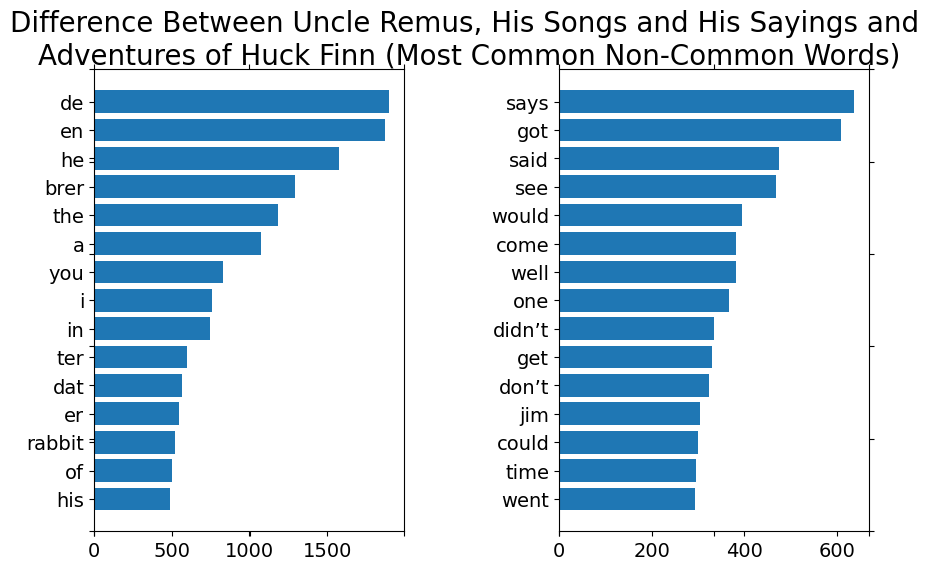

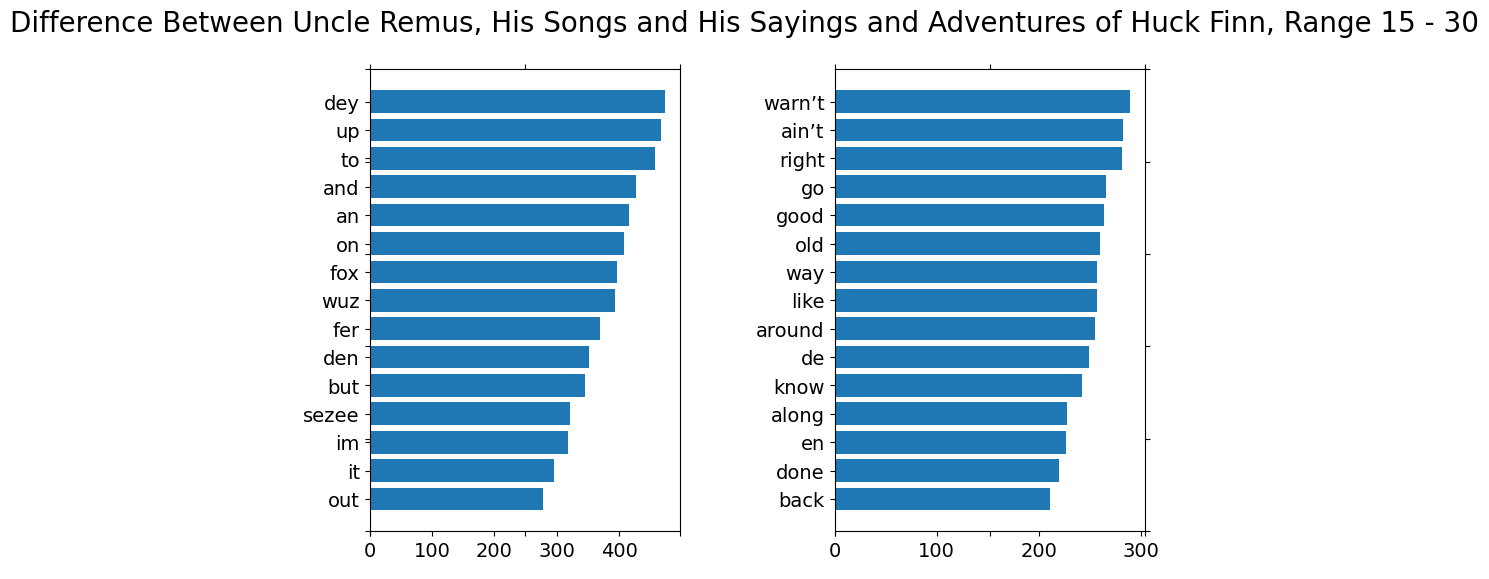

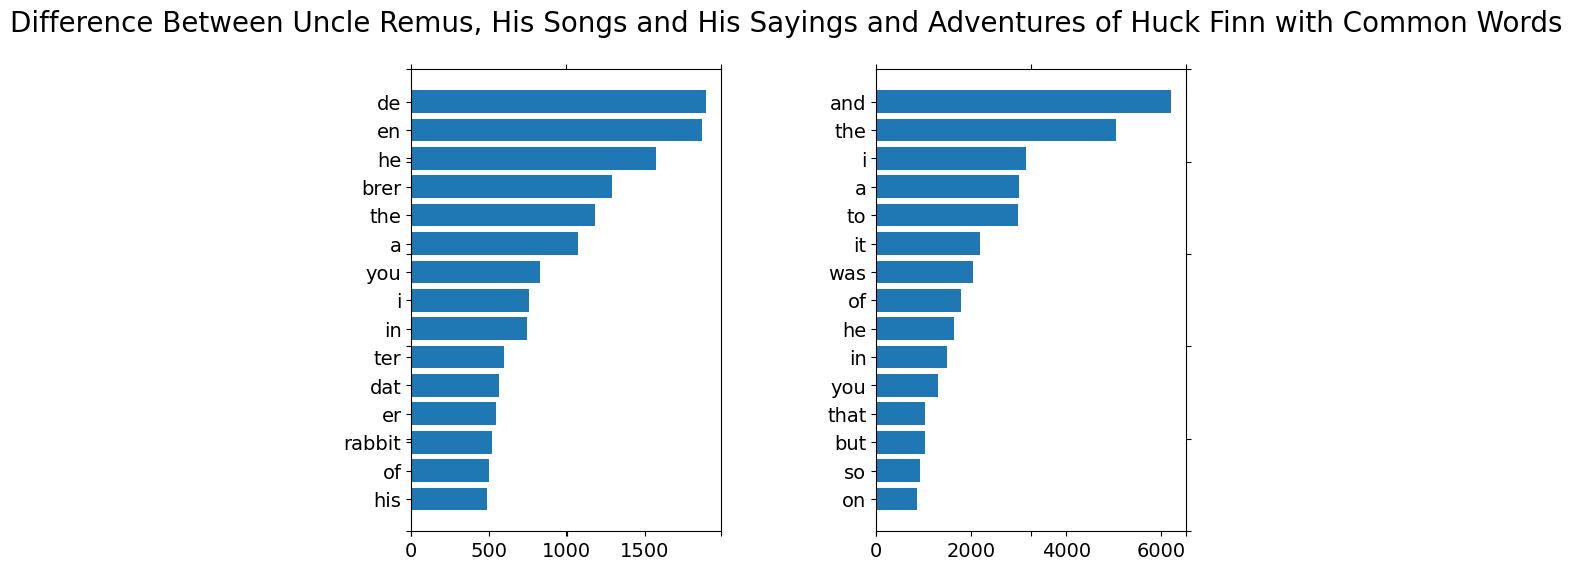

In [27]:
import requests, re, nltk
from bs4 import BeautifulSoup
from nltk import clean_html
from collections import Counter
import operator
import numpy as np
import pylab
import matplotlib.pyplot as plt

nltk.download('stopwords', quiet=True)
# we may not care about the usage of stop words
stop_words = nltk.corpus.stopwords.words('english') + [
 'ut', '\'re','.', ',', '--', '\'s', '?', ')', '(', ':', '\'',
 '"', '-', '}', '{', '&', '|', u'\u2014' ]

# We most likely would like to remove html markup
def cleanHtml (html):
    soup = BeautifulSoup(html, 'html.parser')
    return soup .get_text()

# We also want to remove special characters, quotes, etc. from each word
def cleanWord (w):
    wn = re.sub(r'[,"“.\'&|:@>*;/=]', "", w)
    return re.sub(r'^[0-9\.]*$', "", wn)

# Huckleberry Finn text
tHuck = cleanHtml(requests .get('http://www.gutenberg.org/ebooks/76.txt.utf-8').text).lower()
# Uncle Remus Text
tRemus = cleanHtml(requests.get('http://www.gutenberg.org/ebooks/2306.txt.utf-8').text).lower()

# Split texts into wds and clean each word, filtering out empty strings
wdsRemus = [cleanWord(w) for w in re.split(r'\s+',tRemus) if cleanWord(w)]
wdsHuck = [cleanWord(w) for w in re.split(r'\s+',tHuck) if cleanWord(w)]

# Create dictionaries for each text
dRemus = {}
for w in wdsRemus:
    if w in dRemus: dRemus [w] = dRemus [w] + 1
    else:  dRemus [w] = 1

# Create dictionaries for each text
dHuck = {}
for w in wdsHuck:
    if w in dHuck: dHuck [w] = dHuck [w] + 1
    else:  dHuck [w] = 1

dRemusCommon = dRemus.copy()
dHuckCommon = dHuck.copy()

for k in stop_words:
    dSawyer.pop(k, None)
    dHuck.pop(k, None)

# Sort dictionaries
dsRemus = sorted (dRemus .items(), key = operator .itemgetter (1), reverse=True)
dsHuck = sorted (dHuck .items(), key = operator .itemgetter (1), reverse=True)
dsRemusCommon = sorted (dRemusCommon .items(), key = operator .itemgetter (1), reverse=True)
dsHuckCommon = sorted (dHuckCommon .items(), key = operator .itemgetter (1), reverse=True)

mlRemus = min(len(dsRemus),15)
mlHuck = min(len(dsHuck),15)

%matplotlib inline
def plotTwoLists (wf_ee, wf_bu, title):
    f = plt.figure (figsize=(10, 6))
    # this is painfully tedious....
    f .suptitle (title, fontsize=20)
    ax = f.add_subplot(111)
    ax .spines ['top'] .set_color ('none')
    ax .spines ['bottom'] .set_color ('none')
    ax .spines ['left'] .set_color ('none')
    ax .spines ['right'] .set_color ('none')
    ax .tick_params (labelcolor='w', top='off', bottom='off', left='off', right='off', labelsize=20)

    # Create two subplots, this is the first one
    ax1 = f .add_subplot (121)
    plt .subplots_adjust (wspace=.5)

    pos = np .arange (len(wf_ee))
    ax1 .tick_params (axis='both', which='major', labelsize=14)
    pylab .yticks (pos, [ x [0] for x in wf_ee ])
    ax1 .barh (range(len(wf_ee)), [ x [1] for x in wf_ee ], align='center')

    ax2 = f .add_subplot (122)
    ax2 .tick_params (axis='both', which='major', labelsize=14)
    pos = np .arange (len(wf_bu))
    pylab .yticks (pos, [ x [0] for x in wf_bu ])
    ax2 .barh (range (len(wf_bu)), [ x [1] for x in wf_bu ], align='center')
    plt.show()


# Top 15 words for each story
dsRemusTop = dsRemus[0:mlRemus][::-1]
dsHuckTop = dsHuck[0:mlHuck][::-1]
dsRemusCommon = dsRemusCommon[0:mlRemus][::-1]
dsHuckCommon = dsHuckCommon[0:mlHuck][::-1]

# Less common words
skip_top = 15
take_next = 15

dsRemusSlice = dsRemus[skip_top : skip_top + take_next][::-1]
dsHuckSlice = dsHuck[skip_top : skip_top + take_next][::-1]

# Plot both versions
plotTwoLists(dsRemusTop, dsHuckTop, 'Difference Between Uncle Remus, His Songs and His Sayings and \nAdventures of Huck Finn (Most Common Non-Common Words)')
print("\n")
plotTwoLists(dsRemusSlice, dsHuckSlice, 'Difference Between Uncle Remus, His Songs and His Sayings and \nAdventures of Huck Finn, Range ' + str(skip_top) + ' - ' + str(skip_top + take_next))
print("\n")
plotTwoLists(dsRemusCommon, dsHuckCommon, 'Difference Between Uncle Remus, His Songs and His Sayings and \nAdventures of Huck Finn with Common Words')



# 2. Compare word frequencies between works of two authors.
Next, I compared *Adventures of Huckleberry Finn* to *Uncle Remus, His Songs and His Sayings*. The reason I picked these two stories is due to their usage of a similar dialect. I didn't really have any hypothesis for this comparison, but the results were very interesting. *Uncle Remus* makes a much larger use of the late 1800's southern dialect, as is shown by the graphical comparison with *Huckleberry Finn*. Comparing the most common non-common words, 6 of the 15 words are informal southern dialect in *Uncle Remus*. Compared to *Huckleberry Finn*, which has none of the informal dialect in the top 15 words.

# 3. Are there some words preferred by one author but used less frequently by another author?
As stated in the previous paragraph, Joel Chandler Harris, writer of *Uncle Remus, His Songs and His Sayings* makes a much stronger use of the 1800's southern dialect than Mark Twain, writer of *Adventures of Huckleberry Finn*. Examples of words this would include is, de, en, brer, ter, dat, er, which are all in the top 15 of *Uncle Remus*. *Huckleberry Finn* utilizes this much less, with the highest ranked example being "warn't," which appears at spot number 15.